In [8]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras-tuner]


In [14]:
!pip install pgmpy networkx matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 14.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pgmpy]


/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


MODEL VALIDATION
True

NETWORK NODES
['Cloudy', 'Rain', 'Sprinkler', 'WetGrass']

NETWORK EDGES
[('Cloudy', 'Rain'), ('Cloudy', 'Sprinkler'), ('Rain', 'WetGrass'), ('Sprinkler', 'WetGrass')]

CLOUDY CPD
+-----------+-----+
| Cloudy(0) | 0.5 |
+-----------+-----+
| Cloudy(1) | 0.5 |
+-----------+-----+

RAIN CPD
+---------+-----------+-----------+
| Cloudy  | Cloudy(0) | Cloudy(1) |
+---------+-----------+-----------+
| Rain(0) | 0.8       | 0.2       |
+---------+-----------+-----------+
| Rain(1) | 0.2       | 0.8       |
+---------+-----------+-----------+

SPRINKLER CPD
+--------------+-----------+-----------+
| Cloudy       | Cloudy(0) | Cloudy(1) |
+--------------+-----------+-----------+
| Sprinkler(0) | 0.5       | 0.9       |
+--------------+-----------+-----------+
| Sprinkler(1) | 0.5       | 0.1       |
+--------------+-----------+-----------+

WET GRASS CPD
+-------------+--------------+--------------+--------------+--------------+
| Sprinkler   | Sprinkler(0) | Sprinkler(0

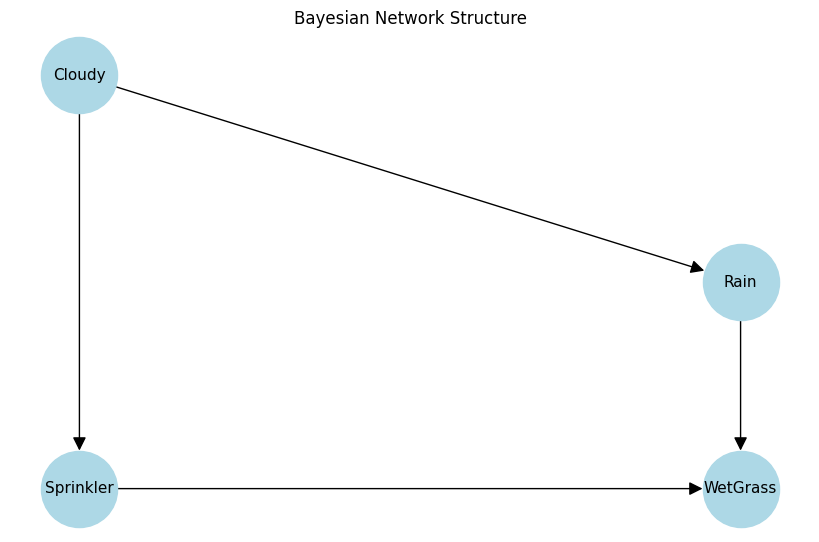

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

# 1. Construct Bayesian Network
model = DiscreteBayesianNetwork([
    ("Cloudy", "Rain"),
    ("Cloudy", "Sprinkler"),
    ("Rain", "WetGrass"),
    ("Sprinkler", "WetGrass")
])

# 2. Define conditional probability distributions

cpd_cloudy = TabularCPD(
    variable="Cloudy",
    variable_card=2,
    values=[[0.5], [0.5]]
)

cpd_sprinkler = TabularCPD(
    variable="Sprinkler",
    variable_card=2,
    values=[
        [0.5, 0.9],
        [0.5, 0.1]
    ],
    evidence=["Cloudy"],
    evidence_card=[2]
)

cpd_rain = TabularCPD(
    variable="Rain",
    variable_card=2,
    values=[
        [0.8, 0.2],
        [0.2, 0.8]
    ],
    evidence=["Cloudy"],
    evidence_card=[2]
)

cpd_wetgrass = TabularCPD(
    variable="WetGrass",
    variable_card=2,
    values=[
        [1.0, 0.1, 0.1, 0.01],
        [0.0, 0.9, 0.9, 0.99]
    ],
    evidence=["Sprinkler", "Rain"],
    evidence_card=[2, 2]
)

# 3. Add CPDs
model.add_cpds(
    cpd_cloudy,
    cpd_sprinkler,
    cpd_rain,
    cpd_wetgrass
)

# 4. Check model
print("MODEL VALIDATION")

print(model.check_model())

print("\nNETWORK NODES")

print(model.nodes())

print("\nNETWORK EDGES")

print(model.edges())

# 5. Display probability distributions
print("\nCLOUDY CPD")

print(cpd_cloudy)

print("\nRAIN CPD")

print(cpd_rain)

print("\nSPRINKLER CPD")

print(cpd_sprinkler)

print("\nWET GRASS CPD")

print(cpd_wetgrass)

# 6. Perform probabilistic inference
inference = VariableElimination(model)

result = inference.query(
    variables=["Rain"]
)

print("\nPROBABILITY OF RAIN")

print(result)

# 7. Evidence-based inference
result2 = inference.query(
    variables=["Rain"],
    evidence={"WetGrass": 1}
)

print("\nPROBABILITY OF RAIN GIVEN WET GRASS")

print(result2)

# 8. Visualize Bayesian Network
G = nx.DiGraph()

G.add_edges_from(model.edges())

pos = {
    "Cloudy": (0, 2),
    "Rain": (2, 1),
    "Sprinkler": (0, 0),
    "WetGrass": (2, 0)
}

plt.figure(figsize=(8, 5))

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=3000,
    node_color="lightblue",
    font_size=11,
    arrows=True,
    arrowsize=20
)

plt.title("Bayesian Network Structure")

plt.axis("off")

plt.show()